## Iterative methods for linear systems

*Examples and notes inspired from Prof. Saswata's notes*

### Jacobi, Gauss–Seidel, and relaxation

Many problems in science and engineering require the solution of a linear
system

$$
A\mathbf x=\mathbf b.
$$

For a small dense matrix, a direct method such as Gaussian elimination is
usually appropriate. Iterative methods become attractive when the matrix is
large, sparse, or must be solved repeatedly. Instead of producing the solution
in one factorization, an iterative method constructs a sequence

$$
\mathbf x^{(0)},\mathbf x^{(1)},\mathbf x^{(2)},\ldots
$$

that is intended to approach the solution.

Iterative, or indirect methods, start with an initial guess of the solution $\mathbf{x}$ and then repeatedly improve the solution until the **change** in $\mathbf{x}$ becomes negligible.

Advantages:
1.
2.


Disadvantages:
1.
2.

### Example Problem

$$
\begin{bmatrix}
4&-1&0\\
-1&4&-1\\
0&-1&3
\end{bmatrix}
\begin{bmatrix}x_1\\x_2\\x_3\end{bmatrix}
=
\begin{bmatrix}15\\10\\10\end{bmatrix}.
$$

In NumPy:

- a matrix is created with `np.array([[...], [...]])`;
- a vector is a one-dimensional `np.array([...])`;
- `A @ x` means the matrix–vector product $A\mathbf x$;
- `A * x` means element-by-element multiplication and is **not** the operation
  in the linear system.

The exact solution is $(5,5,5)^T$. We use it to verify the calculations in
this example.
The iterative algorithms will stop from the **residual**, not by looking at the
known answer.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)

A = np.array([
    [ 4.0, -1.0,  0.0],
    [-1.0,  4.0, -1.0],
    [ 0.0, -1.0,  3.0],
])
b = np.array([15.0, 10.0, 10.0])
x_exact = np.array([5.0, 5.0, 5.0])

In [ ]:
A @ x_exact

array([15., 10., 10.])

### What this calculation shows

The matrix has shape $(3,3)$, so it maps a vector in $\mathbb R^3$ to another
vector in $\mathbb R^3$. The vector $\mathbf b$ has three components, one for
each equation. NumPy confirms that

$$
A
\begin{bmatrix}5\\5\\5\end{bmatrix}
=
\begin{bmatrix}15\\10\\10\end{bmatrix}.
$$

Therefore, $(5,5,5)^T$ is the solution.

In [ ]:
### Gauss-Jacobi

Solving each row for its diagonal variable gives

$$
x_1=\frac{15+x_2}{4},\qquad
x_2=\frac{10+x_1+x_3}{4},\qquad
x_3=\frac{10+x_2}{3}.
$$

Jacobi computes **all** new components from the completed old vector:

$$
x_i^{(k+1)}
=\frac{1}{a_{ii}}
\left(b_i-\sum_{j\ne i}a_{ij}x_j^{(k)}\right).
$$

Starting from $\mathbf x^{(0)}=\mathbf0$, the first sweep is written
explicitly below. Notice that the assignments use `x_old`; none uses a value
already placed in `x_new`.

In [ ]:
x_old = np.zeros(3)
x_new = np.empty(3)

x_new[0] = (15.0 + x_old[1]) / 4.0
x_new[1] = (10.0 + x_old[0] + x_old[2]) / 4.0
x_new[2] = (10.0 + x_old[1]) / 3.0

print("x^(0) =", x_old)
print("x^(1) =", x_new)
print("Residual after one Jacobi sweep =", b - A @ x_new)
print("||residual||_inf =", np.linalg.norm(b - A @ x_new, np.inf))

x^(0) = [0. 0. 0.]
x^(1) = [3.75     2.5      3.333333]
Residual after one Jacobi sweep = [2.5      7.083333 2.5     ]
||residual||_inf = 7.083333333333334


### Interpreting the first Jacobi iteration

Starting from $\mathbf x^{(0)}=\mathbf0$, Jacobi gives

$$
\mathbf x^{(1)}
=
\begin{bmatrix}
15/4\\10/4\\10/3
\end{bmatrix}.
$$

All three components use only values from $\mathbf x^{(0)}$. The residual is
smaller than at the initial vector, but it is not yet close to zero. One sweep
is therefore an update, not a complete solution.

The next cell repeats exactly this rule until the relative residual meets the
chosen tolerance.

### Jacobi Iterations


The matrix form is convenient in NumPy. If

$$
D=\operatorname{diag}(a_{11},\ldots,a_{nn}),
\qquad R=A-D,
$$

then

$$
\mathbf x^{(k+1)}
=D^{-1}\bigl(\mathbf b-R\mathbf x^{(k)}\bigr).
$$

Since $D$ is diagonal, division by `diagonal` is sufficient; we do not form a
matrix inverse.

The stopping rule uses the **relative residual**

$$
\frac{\|\mathbf b-A\mathbf x^{(k)}\|_\infty}
     {\|\mathbf b\|_\infty}<\text{tolerance}.
$$

The maximum sweep count prevents an infinite loop if the method diverges.

In [ ]:
A

array([[ 4., -1.,  0.],
       [-1.,  4., -1.],
       [ 0., -1.,  3.]])

In [ ]:
np.diag(A)

array([4., 4., 3.])

In [ ]:
b

array([15., 10., 10.])

In [ ]:
x_old = np.zeros(3)
x_old

array([0., 0., 0.])

In [ ]:
(b - A @ x_old)/(np.diag(A))

array([3.75    , 2.5     , 3.333333])

In [ ]:
def jacobi(A, b, x0, tolerance=1e-8, max_sweeps=500):
    x = x0.astype(float).copy()
    diagonal = np.diag(A)
    remainder = A - np.diag(diagonal)
    b_norm = np.linalg.norm(b, np.inf)
    residual_history = [np.linalg.norm(b - A @ x, np.inf) / b_norm]

    for sweep in range(1, max_sweeps + 1):
        x_new = (b - remainder @ x) / diagonal
        relative_residual = np.linalg.norm(b - A @ x_new, np.inf) / b_norm
        residual_history.append(relative_residual)
        x = x_new

        if relative_residual < tolerance:
            return x, np.array(residual_history), True

    return x, np.array(residual_history), False

In [ ]:
x_jacobi, residual_jacobi, converged_jacobi = jacobi(
    A, b, np.zeros(3), tolerance=1e-8
)
print("Converged:", converged_jacobi)
print("Jacobi solution =", x_jacobi)
print("Sweeps =", len(residual_jacobi) - 1)
print("Final relative residual =", residual_jacobi[-1])

Converged: True
Jacobi solution = [5. 5. 5.]
Sweeps = 20
Final relative residual = 3.5220672600644322e-09


In [ ]:
print(residual_jacobi)

[1.       0.472222 0.118056 0.068866 0.017216 0.010043 0.002511 0.001465
 0.000366 0.000214 0.000053 0.000031 0.000008 0.000005 0.000001 0.000001
 0.       0.       0.       0.       0.      ]


### What convergence looks like here

The returned vector agrees with $(5,5,5)^T$ to the displayed precision, and the final relative residual is below $10^{-8}$. The Boolean `Converged` is important: a vector returned after reaching `max_sweeps` would not by itself be evidence of convergence.

In [ ]:
### Norm, Residual, Condition Number

## From vector norms to matrix norms

### Measuring the size of a vector

Before we can say that an error or residual is “small,” we need a rule for
measuring the size of a vector. Such a rule is called a **vector norm**.

A vector norm satisfies four properties:

1. $\|\mathbf v\|\geq0$;
2. $\|\mathbf v\|=0$ only when $\mathbf v=\mathbf0$;
3. $\|\alpha\mathbf v\|=|\alpha|\,\|\mathbf v\|$;
4. $\|\mathbf u+\mathbf v\|\leq\|\mathbf u\|+\|\mathbf v\|$.

Three commonly used vector norms are

$$
\boxed{
\|\mathbf v\|_1=\sum_i|v_i|,
\qquad
\|\mathbf v\|_2=\sqrt{\sum_i v_i^2},
\qquad
\|\mathbf v\|_\infty=\max_i|v_i|.}
$$

- $\|\mathbf v\|_1$ adds the magnitudes of all components.
- $\|\mathbf v\|_2$ is the usual Euclidean length.
- $\|\mathbf v\|_\infty$ is the magnitude of the largest component.

Different norms assign different numerical sizes to the same vector, but each
provides a consistent way to compare vectors.

In [ ]:
v = b - A @ x_old

print("v =", v)
print("||v||_1   =", np.linalg.norm(v, 1))
print("||v||_2   =", np.linalg.norm(v, 2))
print("||v||_inf =", np.linalg.norm(v, np.inf))

v = [15. 10. 10.]
||v||_1   = 35.0
||v||_2   = 20.615528128088304
||v||_inf = 15.0


The values differ because the norms ask different questions. The $1$-norm measures total component magnitude, the $2$-norm measures Euclidean length, and the infinity norm reports the largest component. A statement such as “the residual is small” is incomplete unless the norm is specified.

### A matrix acts on vectors

A matrix is not merely a rectangular list of numbers. It represents a linear transformation

$$
\mathbf v \longmapsto A\mathbf v.
$$

Once a vector norm has been chosen, we can ask:

> By what largest factor can $A$ increase the size of a vector?

For a nonzero vector $\mathbf v$, the ratio

$$
\frac{\|A\mathbf v\|_p}{\|\mathbf v\|_p}
$$

is the amplification produced by $A$ in the direction $\mathbf v$. The **induced matrix norm** is the largest possible amplification:

$$
\boxed{
\|A\|_p
=
\max_{\mathbf v\ne\mathbf 0}
\frac{\|A\mathbf v\|_p}{\|\mathbf v\|_p}
=
\max_{\|\mathbf v\|_p=1}\|A\mathbf v\|_p.
}
$$

This definition immediately gives the fundamental consistency property

$$
\boxed{
\|A\mathbf v\|_p
\leq
\|A\|_p\|\mathbf v\|_p
}
$$

for every vector $\mathbf v$. Thus, an induced matrix norm is constructed from a vector norm: the same subscript $p$ is used for the input vector, the output vector, and the matrix norm.

For the three standard induced norms,

$$
\boxed{
\|A\|_1
=
\max_j\sum_i |a_{ij}|
}
\qquad
\text{largest absolute column sum},
$$

$$
\boxed{
\|A\|_\infty
=
\max_i\sum_j |a_{ij}|
}
\qquad
\text{largest absolute row sum},
$$

and

$$
\boxed{
\|A\|_2
=
\sigma_{\max}(A),
}
$$

where $\sigma_{\max}(A)$ denotes the largest singular value of $A$. Singular values will be introduced and explained later. For the moment, $\|A\|_2$ may be understood directly from its definition:

$$
\|A\|_2
=
\max_{\|\mathbf v\|_2=1}
\|A\mathbf v\|_2.
$$

Thus, $\|A\|_2$ is the largest factor by which $A$ can stretch a vector when its length is measured using the Euclidean norm.

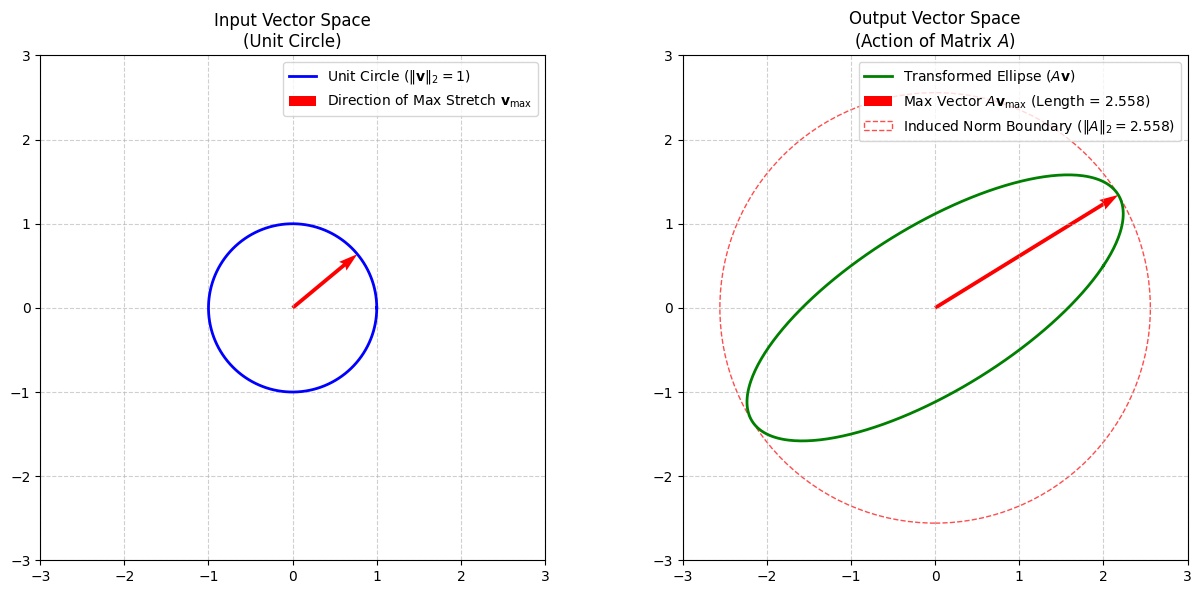

Matrix A:
[[2.  1. ]
 [0.5 1.5]]

Input Vector v_max: [0.7694, 0.6388]
Input Vector Norm ||v_max||_2: 1.0000
Output Vector A*v_max: [2.1776, 1.3428]
Output Vector Norm ||A*v_max||_2: 2.5583
Calculated Induced 2-Norm ||A||_2: 2.5583
NumPy Exact Induced 2-Norm ||A||_2: 2.5583


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Define a non-symmetric 2x2 matrix A
A = np.array([[2.0, 1.0],
              [0.5, 1.5]])

# 2. Generate unit circle vectors (v with ||v||_2 = 1)
theta = np.linspace(0, 2 * np.pi, 400)
V = np.vstack([np.cos(theta), np.sin(theta)])  # 2 x 400 matrix of unit vectors

# 3. Transform unit circle vectors: W = A * V
W = A @ V  # 2 x 400 matrix of transformed vectors

# 4. Compute vector 2-norms for all output vectors ||A v||_2
output_lengths = np.linalg.norm(W, axis=0)

# 5. Find the vector v that produces maximum amplification
max_idx = np.argmax(output_lengths)
v_max = V[:, max_idx]
w_max = W[:, max_idx]
induced_norm_visual = output_lengths[max_idx]

# 6. Verify with NumPy's built-in matrix 2-norm function
induced_norm_exact = np.linalg.norm(A, 2)

# --- Plotting ---
fig, axes = plt.subplots(1, 2, figsize=(13, 6))

# Subplot 1: Input Space (Unit Circle)
axes[0].plot(V[0, :], V[1, :], 'b-', linewidth=2, label=r'Unit Circle ($\|\mathbf{v}\|_2 = 1$)')
axes[0].quiver(0, 0, v_max[0], v_max[1], angles='xy', scale_units='xy', scale=1,
               color='r', linewidth=2, label=r'Direction of Max Stretch $\mathbf{v}_{\max}$')
axes[0].set_aspect('equal')
axes[0].set_xlim(-3, 3)
axes[0].set_ylim(-3, 3)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].set_title("Input Vector Space\n(Unit Circle)", fontsize=12)
axes[0].legend(loc='upper right')

# Subplot 2: Output Space (Transformed Ellipse)
axes[1].plot(W[0, :], W[1, :], 'g-', linewidth=2, label=r'Transformed Ellipse ($A\mathbf{v}$)')
axes[1].quiver(0, 0, w_max[0], w_max[1], angles='xy', scale_units='xy', scale=1,
               color='r', linewidth=2, label=rf'Max Vector $A\mathbf{{v}}_{{\max}}$ (Length = {induced_norm_visual:.3f})')

# Draw bounding circle of radius equal to ||A||_2 to show it is the absolute maximum
bounding_circle = plt.Circle((0, 0), induced_norm_visual, color='r', fill=False,
                             linestyle='--', alpha=0.7, label=rf'Induced Norm Boundary ($\|A\|_2 = {induced_norm_visual:.3f}$)')
axes[1].add_patch(bounding_circle)

axes[1].set_aspect('equal')
axes[1].set_xlim(-3, 3)
axes[1].set_ylim(-3, 3)
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].set_title("Output Vector Space\n(Action of Matrix $A$)", fontsize=12)
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

# Print results
print(f"Matrix A:\n{A}\n")
print(f"Input Vector v_max: [{v_max[0]:.4f}, {v_max[1]:.4f}]")
print(f"Input Vector Norm ||v_max||_2: {np.linalg.norm(v_max):.4f}")
print(f"Output Vector A*v_max: [{w_max[0]:.4f}, {w_max[1]:.4f}]")
print(f"Output Vector Norm ||A*v_max||_2: {np.linalg.norm(w_max):.4f}")
print(f"Calculated Induced 2-Norm ||A||_2: {induced_norm_visual:.4f}")
print(f"NumPy Exact Induced 2-Norm ||A||_2: {induced_norm_exact:.4f}")

### Let's understand the Matrix induced norm

#### Vector Norm Calculation

Take any unit vector $\mathbf{v}$ on the unit circle. For instance, consider the direction along the x-axis:

$$\mathbf{v} = \begin{pmatrix} 1 \\ 0 \end{pmatrix}$$

Its 2-norm is:

$$\Vert{}\mathbf{v}\Vert{}_2 = \sqrt{1^2 + 0^2} = 1$$

Multiplying by $A$ yields the output vector:

$$A\mathbf{v} = \begin{pmatrix} 2 & 1 \\ 0.5 & 1.5 \end{pmatrix} \begin{pmatrix} 1 \\ 0 \end{pmatrix} = \begin{pmatrix} 2 \\ 0.5 \end{pmatrix}$$

The 2-norm of this specific output vector is:

$$\Vert{}A\mathbf{v}\Vert{}_2 = \sqrt{2^2 + 0.5^2} = \sqrt{4.25} \approx 2.0616$$

This shows that in the direction of the x-axis, the matrix $A$ amplifies the vector by a factor of $2.0616$.


**But, this is not the max amplification**

Consider the optimal direction of maximum amplification, $\mathbf{v}_{\max}$:

$$\mathbf{v}_{\max} \approx \begin{pmatrix} 0.7694 \\ 0.6388 \end{pmatrix}$$

Its 2-norm is:

$$\Vert{}\mathbf{v}_{\max}\Vert{}_2 = \sqrt{0.7694^2 + 0.6388^2} = \sqrt{0.5920 + 0.4081} \approx 1$$

Multiplying by $A$ yields the transformed output vector:

$$A\mathbf{v}_{\max} = \begin{pmatrix} 2 & 1 \\ 0.5 & 1.5 \end{pmatrix} \begin{pmatrix} 0.7694 \\ 0.6388 \end{pmatrix} = \begin{pmatrix} 2.1776 \\ 1.3428 \end{pmatrix}$$

The 2-norm of this output vector is:

$$\Vert{}A\mathbf{v}_{\max}\Vert{}_2 = \sqrt{2.1776^2 + 1.3428^2} = \sqrt{4.7419 + 1.8031} = \sqrt{6.5450} \approx 2.5583$$

This maximum value is precisely the induced matrix 2-norm:

$$\Vert{}A\Vert{}_2 = \sigma_{\max}(A) = \sqrt{\lambda_{\max}} = \sqrt{6.5451} \approx 2.5583$$

$$\Vert{}A\Vert{}_2 = \max_{\Vert{}\mathbf{v}\Vert{}_2=1} \Vert{}A\mathbf{v}\Vert{}_2 = \Vert{}A\mathbf{v}_{\max}\Vert{}_2 \approx 2.5583$$

An induced matrix norm describes the largest possible amplification, not the amplification of every vector.

### The Frobenius norm

Another widely used matrix norm is the **Frobenius norm**:

$$
\boxed{
\|A\|_F
=
\left(
\sum_i\sum_j |a_{ij}|^2
\right)^{1/2}.
}
$$

It is obtained by treating all the entries of $A$ as components of one long vector. For example,

$$
A=
\begin{bmatrix}
a & b\\
c & d
\end{bmatrix}
\quad\Longrightarrow\quad
\|A\|_F
=
\sqrt{|a|^2+|b|^2+|c|^2+|d|^2}.
$$

Unlike $\|A\|_1$, $\|A\|_2$, and $\|A\|_\infty$, the Frobenius norm is generally **not an induced matrix norm**. It therefore does not represent the exact maximum amplification of a vector. Instead, it measures the overall magnitude of the entries of the matrix.

Nevertheless, the Frobenius norm satisfies the useful consistency inequality

$$
\boxed{
\|A\mathbf v\|_2
\leq
\|A\|_F\|\mathbf v\|_2.
}
$$

Consequently,

$$
\boxed{
\|A\|_2
\leq
\|A\|_F.
}
$$

Thus, the induced $2$-norm measures the **largest Euclidean stretching caused by $A$**, whereas the Frobenius norm measures the **collective magnitude of all the entries of $A$**.


### Original Example:

$$
\begin{bmatrix}
4&-1&0\\
-1&4&-1\\
0&-1&3
\end{bmatrix}
\begin{bmatrix}x_1\\x_2\\x_3\end{bmatrix}
=
\begin{bmatrix}15\\10\\10\end{bmatrix}.
$$

In [ ]:
A = np.array([
    [ 4.0, -1.0,  0.0],
    [-1.0,  4.0, -1.0],
    [ 0.0, -1.0,  3.0],
])

b = np.array([15.0, 10.0, 10.0])
x_exact = np.array([5.0, 5.0, 5.0])

In [ ]:
absolute_column_sums = np.sum(np.abs(A), axis=0)
absolute_row_sums = np.sum(np.abs(A), axis=1)
singular_values_A = np.linalg.svd(A, compute_uv=False)

print("Absolute column sums =", absolute_column_sums)
print("||A||_1 =", np.max(absolute_column_sums))
print("\nAbsolute row sums =", absolute_row_sums)
print("||A||_inf =", np.max(absolute_row_sums))
print("\nSingular values =", singular_values_A)
print("||A||_2 =", np.max(singular_values_A))

print("\nNumPy checks:")
print("np.linalg.norm(A, 1)      =", np.linalg.norm(A, 1))
print("np.linalg.norm(A, 2)      =", np.linalg.norm(A, 2))
print("np.linalg.norm(A, np.inf) =", np.linalg.norm(A, np.inf))

Absolute column sums = [5. 6. 4.]
||A||_1 = 6.0

Absolute row sums = [5. 6. 4.]
||A||_inf = 6.0

Singular values = [5.24698  3.554958 2.198062]
||A||_2 = 5.246979603717468

NumPy checks:
np.linalg.norm(A, 1)      = 6.0
np.linalg.norm(A, 2)      = 5.246979603717468
np.linalg.norm(A, np.inf) = 6.0


### Measuring residual and error

For an approximation $\widetilde{\mathbf x}$ to the exact solution
$A\mathbf x=\mathbf b$, define

$$
\boxed{\mathbf r=\mathbf b-A\widetilde{\mathbf x}}
\qquad\text{and}\qquad
\boxed{\mathbf e=\mathbf x-\widetilde{\mathbf x}.}
$$

- The **residual** $\mathbf r$ measures how well the approximation satisfies
  the equations. It can be computed because $A$, $\mathbf b$, and
  $\widetilde{\mathbf x}$ are known.
- The **error** $\mathbf e$ measures the distance from the exact solution. It
  is normally unavailable because $\mathbf x$ is unknown.

Since $\mathbf b=A\mathbf x$,

$$
\mathbf r
=A\mathbf x-A\widetilde{\mathbf x}
=A(\mathbf x-\widetilde{\mathbf x})
=A\mathbf e.
$$

The induced norm property gives

$$
\|\mathbf r\|_p
=\|A\mathbf e\|_p
\leq
\|A\|_p\|\mathbf e\|_p.
$$

To obtain an upper bound on the error from the residual, we need $A^{-1}$:

$$
\mathbf e=A^{-1}\mathbf r,
\qquad
\|\mathbf e\|_p\leq\|A^{-1}\|_p\|\mathbf r\|_p.
$$

This is the point at which the condition number enters the discussion.

In [ ]:
x_exact = np.array([5.0, 5.0, 5.0])
x_trial = np.array([4.9, 5.1, 5.0])

r_trial = b - A @ x_trial
e_trial = x_exact - x_trial

print("Trial approximation =", x_trial)
print("Residual b - A @ x_trial =", r_trial)
print("||residual||_inf =", np.linalg.norm(r_trial, np.inf))
print("True error =", e_trial)
print("||true error||_inf =", np.linalg.norm(e_trial, np.inf))

Trial approximation = [4.9 5.1 5. ]
Residual b - A @ x_trial = [ 0.5 -0.5  0.1]
||residual||_inf = 0.4999999999999982
True error = [ 0.1 -0.1  0. ]
||true error||_inf = 0.09999999999999964


### What can and cannot be concluded

The trial vector has infinity-norm error $0.1$, whereas its infinity-norm
residual is $0.5$. These numbers need not be equal because

$$
\mathbf r=A\mathbf e.
$$

The matrix changes the size and direction of the error before we observe it as
a residual. During a real solve, the residual can be computed but the true
error cannot. We therefore need to know how strongly $A^{-1}$ can amplify the
residual. That sensitivity is measured by the condition number.

### Eigenvalues, eigenvectors, spectral radius

For most vectors, multiplication by a matrix changes both length and
direction. An **eigenvector** is a special nonzero vector whose direction is
unchanged:

$$
\boxed{A\mathbf q=\lambda\mathbf q.}
$$

The scalar $\lambda$ is the corresponding **eigenvalue**.

- If $\lambda>1$, the eigenvector is stretched.
- If $0<\lambda<1$, it is shortened.
- If $\lambda<0$, its direction is reversed as well as scaled.
- If $\lambda=0$, the eigenvector is mapped to zero and $A$ is singular.

Eigenvalues are obtained from

$$
\det(A-\lambda I)=0.
$$

For a real symmetric matrix, all eigenvalues are real and its eigenvectors can
be chosen to be mutually orthonormal. In NumPy, `np.linalg.eigh` is designed
for real symmetric matrices; `np.linalg.eig` handles a general square matrix.

### Spectral radius

The **spectral radius** is the largest eigenvalue magnitude:

$$
\boxed{\rho(A)
=\max_{\lambda\in\operatorname{spec}(A)}|\lambda|.}
$$

$\operatorname{spec}(A)$ means the spectrum of the matrix $A$, that is, the set of all eigenvalues of $A$:

$$
\boxed{
\operatorname{spec}(A)={\lambda:\det(A−\lambda I)=0}}
$$.

Therefore,

$$
\rho(A)
=
\max_{\lambda\in\operatorname{spec}(A)}|\lambda|
$$

means:

> Find all eigenvalues of $A$, take their absolute values, and choose the largest one.

For example, suppose the eigenvalues of $A$ are

$$
\lambda_1=0.4,
\qquad
\lambda_2=-0.8,
\qquad
\lambda_3=0.2+0.6i.
$$

Then

$$
\operatorname{spec}(A)
=
\{0.4,-0.8,0.2+0.6i\}.
$$

Their magnitudes are

$$
|\lambda_1|=0.4,
\qquad
|\lambda_2|=0.8,
\qquad
|\lambda_3|
=
\sqrt{0.2^2+0.6^2}
=
\sqrt{0.4}
\approx 0.632.
$$

Hence,

$$
\boxed{
\rho(A)=0.8.
}
$$

For an introductory treatment, the definition may be written more transparently as

$$
\boxed{
\rho(A)=\max_i|\lambda_i|,
}
$$

where $\lambda_1,\lambda_2,\ldots,\lambda_n$ are the eigenvalues of $A$.

The set of all eigenvalues of $A$ is called the **spectrum** of $A$ and is denoted by

$$
\operatorname{spec}(A).
$$







It is especially important when a matrix is applied repeatedly. If

$$
\mathbf e^{(k+1)}=T\mathbf e^{(k)},
$$

then $\mathbf e^{(k)}=T^k\mathbf e^{(0)}$. A stationary iteration converges
for every initial error exactly when

$$
\boxed{\rho(T)<1.}
$$

### Why does $\rho(T)<1$ imply convergence?

Suppose $T$ has eigenvectors $\mathbf v_i$ with corresponding eigenvalues $\lambda_i$:

$$
T\mathbf v_i=\lambda_i\mathbf v_i.
$$

After applying $T$ repeatedly,

$$
T^k\mathbf v_i=\lambda_i^k\mathbf v_i.
$$

Thus, each eigenvector component of the initial error is multiplied by
$\lambda_i^k$. If every eigenvalue satisfies $|\lambda_i|<1$, then

$$
\lambda_i^k\longrightarrow 0
\qquad\text{as}\qquad
k\longrightarrow\infty.
$$

Therefore,

$$
T^k\mathbf e^{(0)}\longrightarrow \mathbf 0,
$$

and the iteration converges.

---

#### Example: convergent iteration

Consider

$$
T=
\begin{bmatrix}
0.8 & 0\\
0 & 0.4
\end{bmatrix}.
$$

Its eigenvalues are $0.8$ and $0.4$, so

$$
\rho(T)=0.8<1.
$$

For an initial error

$$
\mathbf e^{(0)}
=
\begin{bmatrix}
1\\
1
\end{bmatrix},
$$

we obtain

$$
\mathbf e^{(k)}
=
T^k\mathbf e^{(0)}
=
\begin{bmatrix}
0.8^k\\
0.4^k
\end{bmatrix}.
$$

The first few errors are

$$
\mathbf e^{(0)}
=
\begin{bmatrix}
1\\
1
\end{bmatrix},
\qquad
\mathbf e^{(1)}
=
\begin{bmatrix}
0.8\\
0.4
\end{bmatrix},
$$

$$
\mathbf e^{(2)}
=
\begin{bmatrix}
0.64\\
0.16
\end{bmatrix},
\qquad
\mathbf e^{(3)}
=
\begin{bmatrix}
0.512\\
0.064
\end{bmatrix}.
$$

Both components decrease toward zero:

$$
\mathbf e^{(k)}\longrightarrow\mathbf 0.
$$

---

#### Example: divergent iteration

Now consider

$$
T=
\begin{bmatrix}
1.1 & 0\\
0 & 0.4
\end{bmatrix}.
$$

Here,

$$
\rho(T)=1.1>1.
$$

For the same initial error,

$$
\mathbf e^{(k)}
=
\begin{bmatrix}
1.1^k\\
0.4^k
\end{bmatrix}.
$$

Although the second component decays, the first component grows. Therefore, the error does not approach zero, and the iteration diverges.

---

The spectral radius therefore identifies the slowest-decaying or fastest-growing eigenvector component:

$$
\boxed{
\rho(T)<1
\quad\Longrightarrow\quad
\text{all eigenvector components decay}.
}
$$

$$
\boxed{
\rho(T)>1
\quad\Longrightarrow\quad
\text{at least one eigenvector component grows}.
}
$$


In [ ]:
### General Iterative Framework

## From $A=D+L+U$ to the iteration matrix

Write the coefficient matrix as

$$
\boxed{A=D+L+U,}
$$

where:

- $D$ contains the diagonal entries of $A$;
- $L$ contains the entries strictly below the diagonal;
- $U$ contains the entries strictly above the diagonal.

Here, $L$ and $U$ contain the actual entries of $A$, including their signs.

### Jacobi

Starting from

$$
(D+L+U)\mathbf x=\mathbf b,
$$

Jacobi evaluates all off-diagonal terms using the old vector:

$$
D\mathbf x^{(k+1)}
=\mathbf b-(L+U)\mathbf x^{(k)}.
$$

Solving with the diagonal matrix $D$ gives

$$
\mathbf x^{(k+1)}
=-D^{-1}(L+U)\mathbf x^{(k)}
+D^{-1}\mathbf b.
$$

Comparing this with

$$
\mathbf x^{(k+1)}=T\mathbf x^{(k)}+\mathbf c
$$

identifies

$$
\boxed{
T_J=-D^{-1}(L+U),
\qquad
\mathbf c_J=D^{-1}\mathbf b.}
$$

In [ ]:
D_split = np.diag(np.diag(A))
L_split = np.tril(A, -1)
U_split = np.triu(A, 1)

T_jacobi = -np.linalg.solve(D_split, L_split + U_split)
c_jacobi = np.linalg.solve(D_split, b)

T_gs = -np.linalg.solve(D_split + L_split, U_split)
c_gs = np.linalg.solve(D_split + L_split, b)

x0_split = np.zeros(3)
x1_jacobi_from_split = T_jacobi @ x0_split + c_jacobi

print("D =\n", D_split)
print("\nL =\n", L_split)
print("\nU =\n", U_split)
print("\nDoes D + L + U reproduce A?",
      np.allclose(D_split + L_split + U_split, A))

print("\nJacobi")
print("T_J =\n", T_jacobi)
print("c_J =", c_jacobi)
print("T_J @ x^(0) + c_J =", x1_jacobi_from_split)

print("Fixed-point check:",
      np.allclose(T_jacobi @ x_exact + c_jacobi, x_exact))

D =
 [[4. 0. 0.]
 [0. 4. 0.]
 [0. 0. 3.]]

L =
 [[ 0.  0.  0.]
 [-1.  0.  0.]
 [ 0. -1.  0.]]

U =
 [[ 0. -1.  0.]
 [ 0.  0. -1.]
 [ 0.  0.  0.]]

Does D + L + U reproduce A? True

Jacobi
T_J =
 [[-0.        0.25     -0.      ]
 [ 0.25     -0.        0.25    ]
 [-0.        0.333333 -0.      ]]
c_J = [3.75     2.5      3.333333]
T_J @ x^(0) + c_J = [3.75     2.5      3.333333]
Fixed-point check: True


In [ ]:
## Exact solution satisfies the iterative scheme (it is called the fixed point)

T_jacobi @ x_exact + c_jacobi

array([5., 5., 5.])

### Interpreting the numerical splitting

The calculation first verifies

$$
A=D+L+U.
$$

Starting from $\mathbf x^{(0)}=\mathbf0$,

$$
\mathbf x^{(1)}
=T\mathbf0+\mathbf c
=\mathbf c.
$$

Therefore, $\mathbf c_J$ is exactly the first Jacobi sweep:

$$
\mathbf c_J
=
\begin{bmatrix}
3.75\\2.50\\3.3333
\end{bmatrix},
$$

The fixed-point checks verify that the exact solution satisfies

$$
\mathbf x^\ast=T_J\mathbf x^\ast+\mathbf c_J
$$


The matrix $T$ determines how the current error is transformed from one sweep to the
next. We can now explain why the eigenvalues of $T$ control convergence.

### Why the spectral radius controls convergence

Every stationary method can be written

$$
\mathbf x^{(k+1)}=T\mathbf x^{(k)}+\mathbf c.
$$

Let $\mathbf x^\ast$ denote the exact solution. Because it is a fixed point of
the iteration,

$$
\mathbf x^\ast=T\mathbf x^\ast+\mathbf c.
$$

Define the error at sweep $k$ by

$$
\mathbf e^{(k)}=\mathbf x^\ast-\mathbf x^{(k)}.
$$

Subtracting the numerical iteration from the fixed-point equation gives

$$
\boxed{\mathbf e^{(k+1)}=T\mathbf e^{(k)}.}
$$

Repeating this relation gives

$$
\boxed{\mathbf e^{(k)}=T^k\mathbf e^{(0)}.}
$$

The iteration therefore converges from every initial vector precisely when
$T^k\mathbf e^{(0)}$ approaches zero for every possible initial error.

### Why eigenvalues determine the answer

Suppose $\mathbf q_i$ is an eigenvector of $T$:

$$
T\mathbf q_i=\lambda_i\mathbf q_i.
$$

Repeated multiplication gives

$$
T^k\mathbf q_i=\lambda_i^k\mathbf q_i.
$$

Thus, an error component in the direction $\mathbf q_i$ is multiplied by
$\lambda_i$ at every sweep. If $T$ is diagonalizable and

$$
\mathbf e^{(0)}=\sum_i\alpha_i\mathbf q_i,
$$

then

$$
\boxed{
\mathbf e^{(k)}
=\sum_i\alpha_i\lambda_i^k\mathbf q_i.}
$$

Therefore:

- if $|\lambda_i|<1$, that error mode decays;
- if $\lambda_i<0$, the mode alternates sign while its magnitude changes;
- if $|\lambda_i|>1$, that mode grows;
- if $|\lambda_i|=1$, that mode does not decay.

The slowest-decaying or fastest-growing mode is determined by the spectral
radius

$$
\boxed{
\rho(T)
=\max_{\lambda\in\operatorname{spec}(T)}|\lambda|.}
$$

Hence, a stationary iteration converges for **every** initial vector exactly
when

$$
\boxed{\rho(T)<1.}
$$

This criterion also remains exact when $T$ is not diagonalizable. The
eigenvector argument above gives the clearest geometric interpretation.

Convergent example
Eigenvalues = [ 0.6 -0.2]
rho(T) = 0.6
 k     first mode    second mode
 0       1.000000       1.000000
 1       0.600000      -0.200000
 2       0.360000       0.040000
 3       0.216000      -0.008000
 4       0.129600       0.001600
 5       0.077760      -0.000320
 6       0.046656       0.000064

Divergent example
Eigenvalues = [0.6  1.05]
rho(T) = 1.05
 k     first mode    second mode
 0       1.000000       1.000000
 1       0.600000       1.050000
 2       0.360000       1.102500
 3       0.216000       1.157625
 4       0.129600       1.215506
 5       0.077760       1.276282
 6       0.046656       1.340096


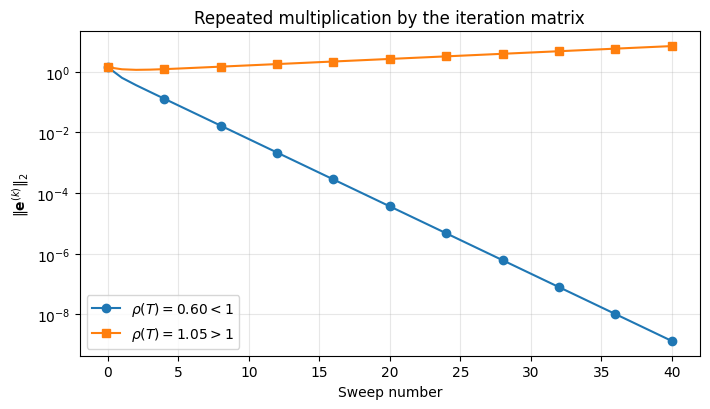

In [ ]:
T_convergent = np.array([[0.60,  0.00],
                         [0.00, -0.20]])
T_divergent = np.array([[0.60, 0.00],
                        [0.00, 1.05]])
initial_error = np.array([1.0, 1.0])


def error_history(T, error_0, number_of_sweeps):
    error = error_0.copy()
    history = [error.copy()]
    for _ in range(number_of_sweeps):
        error = T @ error
        history.append(error.copy())
    return np.array(history)


good_errors = error_history(T_convergent, initial_error, 40)
bad_errors = error_history(T_divergent, initial_error, 40)

print("Convergent example")
print("Eigenvalues =", np.linalg.eigvals(T_convergent))
print("rho(T) =", np.max(np.abs(np.linalg.eigvals(T_convergent))))
print(f"{'k':>2s} {'first mode':>14s} {'second mode':>14s}")
for k in range(7):
    print(f"{k:2d} {good_errors[k, 0]:14.6f} "
          f"{good_errors[k, 1]:14.6f}")

print("\nDivergent example")
print("Eigenvalues =", np.linalg.eigvals(T_divergent))
print("rho(T) =", np.max(np.abs(np.linalg.eigvals(T_divergent))))
print(f"{'k':>2s} {'first mode':>14s} {'second mode':>14s}")
for k in range(7):
    print(f"{k:2d} {bad_errors[k, 0]:14.6f} "
          f"{bad_errors[k, 1]:14.6f}")

sweeps = np.arange(len(good_errors))
good_norms = np.linalg.norm(good_errors, axis=1)
bad_norms = np.linalg.norm(bad_errors, axis=1)

plt.figure(figsize=(7.2, 4.2))
plt.semilogy(sweeps, good_norms, "o-", markevery=4,
             label=r"$\rho(T)=0.60<1$")
plt.semilogy(sweeps, bad_norms, "s-", markevery=4,
             label=r"$\rho(T)=1.05>1$")
plt.xlabel("Sweep number")
plt.ylabel(r"$\|\mathbf{e}^{(k)}\|_2$")
plt.title("Repeated multiplication by the iteration matrix")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Interpreting the two-mode example

For the convergent matrix,

$$
\mathbf e^{(k)}
=
\begin{bmatrix}
0.6^k\\(-0.2)^k
\end{bmatrix}.
$$

Both components approach zero. The second component alternates sign because
its eigenvalue is negative, but its magnitude decreases rapidly. The first
component eventually dominates because $0.6$ has the larger magnitude.

For the divergent matrix,

$$
\mathbf e^{(k)}
=
\begin{bmatrix}
0.6^k\\1.05^k
\end{bmatrix}.
$$

The first component decays, but the second grows. The total error can even
decrease during the first few sweeps while the decaying mode is still large.
Eventually the growing mode dominates. Thus, observing a few decreasing
residuals or errors is not by itself a proof of convergence.

In [ ]:
## Jacobi Iteration Matrix

T_jacobi

array([[-0.      ,  0.25    , -0.      ],
       [ 0.25    , -0.      ,  0.25    ],
       [-0.      ,  0.333333, -0.      ]])

In [ ]:
eigenvalues_jacobi = np.linalg.eigvals(T_jacobi)

rho_jacobi = np.max(np.abs(eigenvalues_jacobi))


print("T_Jacobi =\n", T_jacobi)
print("Eigenvalues of T_Jacobi =", eigenvalues_jacobi)
print("rho(T_Jacobi)       =", rho_jacobi)

print("Spectral radii below one:", rho_jacobi < 1)

T_Jacobi =
 [[-0.        0.25     -0.      ]
 [ 0.25     -0.        0.25    ]
 [-0.        0.333333 -0.      ]]
Eigenvalues of T_Jacobi = [-0.381881  0.        0.381881]
rho(T_Jacobi)       = 0.3818813079129867
Spectral radii below one: True


### Why iterations converge

Spectral radii is below $1$, so repeated multiplication by the iteration matrix drives every initial error to zero.

For Jacobi, the two largest-magnitude eigenvalues have equal magnitude and opposite signs. Consequently, some error components alternate sign as they decay.

This calculation concerns the iteration matrices $T_J$ and $T_{GS}$, not the coefficient matrix $A$ itself. In particular, $\rho(A)<1$ is not the convergence condition for Jacobi.

In [ ]:
### Gauss-Seidel

## Gauss–Seidel: reusing new values immediately

Gauss–Seidel uses $x_j^{(k+1)}$ as soon as it is available:

$$
x_i^{(k+1)}
=\frac{1}{a_{ii}}
\left(
b_i-\sum_{j<i}a_{ij}x_j^{(k+1)}
   -\sum_{j>i}a_{ij}x_j^{(k)}
\right).
$$

The following cell performs one sweep without a loop so the data dependence is
visible.

In [ ]:
x_old = np.zeros(3)
x_new = x_old.copy()

x_new[0] = (15.0 + x_old[1]) / 4.0
x_new[1] = (10.0 + x_new[0] + x_old[2]) / 4.0  # new x_1
x_new[2] = (10.0 + x_new[1]) / 3.0             # new x_2

print("x^(0) =", x_old)
print("x^(1) =", x_new)
print("Residual after one Gauss-Seidel sweep =", b - A @ x_new)
print("||residual||_inf =", np.linalg.norm(b - A @ x_new, np.inf))

x^(0) = [0. 0. 0.]
x^(1) = [3.75     3.4375   4.479167]
Residual after one Gauss-Seidel sweep = [3.4375   4.479167 0.      ]
||residual||_inf = 4.479166666666667


### Why this sweep differs from Jacobi

The first Gauss–Seidel component is the same as the first Jacobi component.
The second component immediately uses that new $x_1^{(1)}$, and the third
immediately uses the new $x_2^{(1)}$. Information therefore travels through
the variables during a single sweep.

This often reduces the number of sweeps, but it also makes the calculation
sequential and dependent on the ordering of the equations and unknowns.

## Gauss–Seidel implementation and fair comparison

Within one sweep, `x[:i]` already contains new values while `x_old[i+1:]`
contains the not-yet-updated old values. We compare with Jacobi using the same
initial vector and the same relative-residual tolerance.

Method             Sweeps   Final relative residual
----------------------------------------------------
Jacobi                 20                 3.522e-09
Gauss-Seidel           11                 2.654e-09


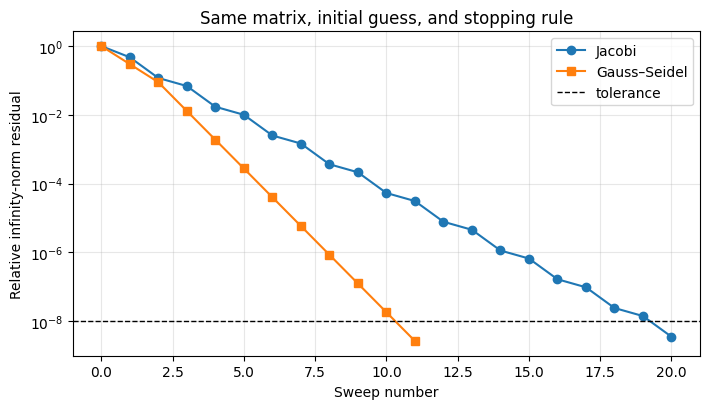

In [ ]:
def gauss_seidel(A, b, x0, tolerance=1e-8, max_sweeps=500, omega=1.0):
    x = x0.astype(float).copy()
    b_norm = np.linalg.norm(b, np.inf)
    residual_history = [np.linalg.norm(b - A @ x, np.inf) / b_norm]

    for sweep in range(1, max_sweeps + 1):
        x_old = x.copy()

        for i in range(len(b)):
            sum_with_new_values = A[i, :i] @ x[:i]
            sum_with_old_values = A[i, i + 1:] @ x_old[i + 1:]
            ordinary_gs_value = (
                b[i] - sum_with_new_values - sum_with_old_values
            ) / A[i, i]
            x[i] = (1.0 - omega) * x_old[i] + omega * ordinary_gs_value

        relative_residual = np.linalg.norm(b - A @ x, np.inf) / b_norm
        residual_history.append(relative_residual)

        if relative_residual < tolerance:
            return x, np.array(residual_history), True

    return x, np.array(residual_history), False


x_gs, residual_gs, converged_gs = gauss_seidel(
    A, b, np.zeros(3), tolerance=1e-8
)

print(f"{'Method':16s} {'Sweeps':>8s} {'Final relative residual':>25s}")
print("-" * 52)
print(f"{'Jacobi':16s} {len(residual_jacobi)-1:8d} {residual_jacobi[-1]:25.3e}")
print(f"{'Gauss-Seidel':16s} {len(residual_gs)-1:8d} {residual_gs[-1]:25.3e}")

plt.figure(figsize=(7.2, 4.2))
plt.semilogy(residual_jacobi, "o-", label="Jacobi")
plt.semilogy(residual_gs, "s-", label="Gauss–Seidel")
plt.axhline(1e-8, color="black", linestyle="--", linewidth=1,
            label="tolerance")
plt.xlabel("Sweep number")
plt.ylabel("Relative infinity-norm residual")
plt.title("Same matrix, initial guess, and stopping rule")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

- Gauss–Seidel often needs fewer sweeps because it reuses information
  immediately.
- A Gauss–Seidel sweep is sequential and depends on the ordering.
- Jacobi components are independent within a sweep, which is useful for
  vectorization and parallel computation.
- Therefore, “fewer sweeps” and “less elapsed time” are not identical claims.

For this small serial NumPy example, Gauss–Seidel reaches the tolerance in
fewer sweeps.

In [ ]:
### SUR, Gauss-Seidel, SOR

## SUR, Gauss–Seidel, and SOR

Let $\widehat{x}_i^{(k+1)}$ be the ordinary Gauss–Seidel update. Relaxation
uses

$$
x_i^{(k+1)}
=(1-\omega)x_i^{(k)}+\omega\widehat{x}_i^{(k+1)}.
$$

- $0<\omega<1$: **successive under-relaxation (SUR)**; damping may improve
  robustness but usually costs more sweeps.
- $\omega=1$: ordinary **Gauss–Seidel**.
- $1<\omega<2$: **successive over-relaxation (SOR)**; a suitable value can
  accelerate convergence, but a larger value is not automatically better.

The `gauss_seidel` function already contains this formula through its `omega`
argument. We now compare all methods using the same **relative** residual
tolerance $10^{-8}$.

method            omega     rho(T)   sweeps
--------------------------------------------
SUR                0.80     0.3910       20
Gauss-Seidel       1.00     0.1458       11
mild SOR           1.05     0.0500        7
stronger SOR       1.20     0.2000       12


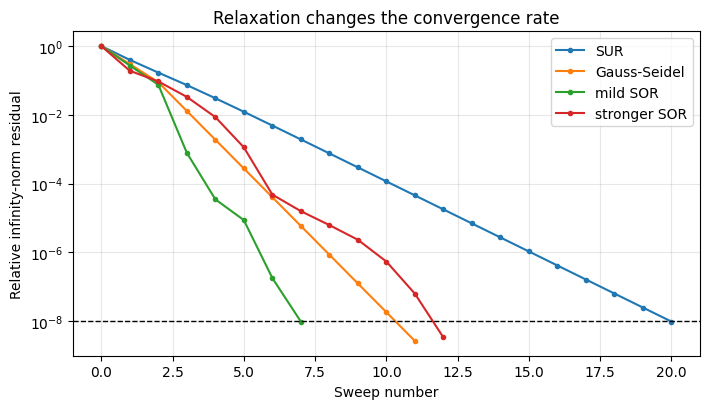

In [ ]:
def iteration_matrix(A, method="jacobi", omega=1.0):
    '''Return the stationary iteration matrix T for A=D+L+U.'''
    D = np.diag(np.diag(A))
    L = np.tril(A, -1)
    U = np.triu(A, 1)
    if method == "jacobi":
        return -np.linalg.solve(D, L + U)
    if method == "gauss-seidel":
        return -np.linalg.solve(D + L, U)
    if method == "sor":
        return np.linalg.solve(
            D + omega * L,
            (1.0 - omega) * D - omega * U,
        )
    raise ValueError("Unknown method.")


cases = [
    ("SUR", 0.80),
    ("Gauss-Seidel", 1.00),
    ("mild SOR", 1.05),
    ("stronger SOR", 1.20),
]

results = {}
print(f"{'method':16s} {'omega':>6s} {'rho(T)':>10s} {'sweeps':>8s}")
print("-" * 44)
for name, omega in cases:
    x_result, history, converged = gauss_seidel(
        A, b, np.zeros(3), tolerance=1e-8,
        max_sweeps=1_000, omega=omega
    )
    T = iteration_matrix(A, method="sor", omega=omega)
    rho = np.max(np.abs(np.linalg.eigvals(T)))
    results[name] = history
    print(f"{name:16s} {omega:6.2f} {rho:10.4f} "
          f"{len(history)-1:8d}")

plt.figure(figsize=(7.2, 4.2))
for name, _ in cases:
    plt.semilogy(results[name], marker=".", label=name)
plt.axhline(1e-8, color="black", ls="--", lw=1)
plt.xlabel("Sweep number")
plt.ylabel("Relative infinity-norm residual")
plt.title("Relaxation changes the convergence rate")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

The table and graph compare methods using the same matrix, initial vector, and
stopping rule. Here, mild over-relaxation improves the convergence rate, while
under-relaxation damps the update and takes more sweeps.

This is an example, not a universal ranking. The useful value of $\omega$
depends on the matrix. A value that accelerates one system may slow or even
destabilize another. The spectral radius column explains the observed
asymptotic rates: smaller $\rho(T_\omega)$ generally means faster decay after
the transient behavior.

In [ ]:
### Condition number, spectral radius

### Recall (Measuring residual and error)

For an approximation $\widetilde{\mathbf x}$ to the exact solution
$A\mathbf x=\mathbf b$, define

$$
\boxed{\mathbf r=\mathbf b-A\widetilde{\mathbf x}}
\qquad\text{and}\qquad
\boxed{\mathbf e=\mathbf x-\widetilde{\mathbf x}.}
$$

- The **residual** $\mathbf r$ measures how well the approximation satisfies
  the equations. It can be computed because $A$, $\mathbf b$, and
  $\widetilde{\mathbf x}$ are known.
- The **error** $\mathbf e$ measures the distance from the exact solution. It
  is normally unavailable because $\mathbf x$ is unknown.

Since $\mathbf b=A\mathbf x$,

$$
\mathbf r
=A\mathbf x-A\widetilde{\mathbf x}
=A(\mathbf x-\widetilde{\mathbf x})
=A\mathbf e.
$$

The induced norm property gives

$$
\|\mathbf r\|_p
=\|A\mathbf e\|_p
\leq
\|A\|_p\|\mathbf e\|_p.
$$

To obtain an upper bound on the error from the residual, we need $A^{-1}$:

$$
\mathbf e=A^{-1}\mathbf r,
\qquad
\|\mathbf e\|_p\leq\|A^{-1}\|_p\|\mathbf r\|_p.
$$

This is the point at which the condition number enters the discussion.

### Condition Number and sensitivity

For a nonsingular matrix and an induced matrix norm, the condition number is

$$
\boxed{\kappa_p(A)=\|A\|_p\|A^{-1}\|_p.}
$$

The value depends on the chosen norm.

The condition number measures how much the relative error in the solution can be magnified relative to the relative residual.

- Because $\Vert{}A\Vert{}_p \Vert{}A^{-1}\Vert{}_p \ge \Vert{}A A^{-1}\Vert{}_p = \Vert{}I\Vert{}_p = 1$, we always have $\kappa_p(A) \ge 1$.

---

**Relative Error Bound**

* Since $A\mathbf{x} = \mathbf{b}$, applying the consistency property of induced norms gives:

$$\Vert{}\mathbf{b}\Vert{}_p = \Vert{}A\mathbf{x}\Vert{}_p \le \Vert{}A\Vert{}_p \Vert{}\mathbf{x}\Vert{}_p$$

* Assuming $\mathbf{b} \neq \mathbf{0}$ (and thus $\mathbf{x} \neq \mathbf{0}$), dividing both sides by $\Vert{}\mathbf{b}\Vert{}_p \Vert{}\mathbf{x}\Vert{}_p$ gives:

$$\boxed{\frac{1}{\Vert{}\mathbf{x}\Vert{}_p} \le \frac{\Vert{}A\Vert{}_p}{\Vert{}\mathbf{b}\Vert{}_p}}$$

* Since $A\mathbf{e} = \mathbf{r}$, multiplying both sides by $A^{-1}$ gives $\mathbf{e} = A^{-1}\mathbf{r}$. Applying the induced norm gives:

$$\boxed{\Vert{}\mathbf{e}\Vert{}_p \le \Vert{}A^{-1}\Vert{}_p \Vert{}\mathbf{r}\Vert{}_p}$$

* Combining both inequalities:


$$\boxed{ \frac{\Vert{}\mathbf{e}\Vert{}_p}{\Vert{}\mathbf{x}\Vert{}_p}  \le  \kappa_p(A) \frac{\Vert{}\mathbf{r}\Vert{}_p}{\Vert{}\mathbf{b}\Vert{}_p} }$$

A small residual is strong evidence of a small relative error only when the
condition number is not too large.

NumPy computes this quantity with `np.linalg.cond(A, 2)`. There is no need to
form $A^{-1}$ explicitly.

- $\kappa(A)\geq1$ for every nonsingular matrix.
- $\kappa(A)$ close to $1$ indicates low sensitivity.
- A large $\kappa(A)$ indicates that some perturbations can be strongly
  amplified.
- If $A$ is singular, $\sigma_{\min}=0$ and $\kappa_2(A)=\infty$.

In [ ]:
A

array([[ 4., -1.,  0.],
       [-1.,  4., -1.],
       [ 0., -1.,  3.]])

In [ ]:
np.linalg.cond(A)

np.float64(2.3870932544482275)

For the recurring matrix, $\kappa_2(A)$ is modest. The actual relative error
is below

$$
\kappa_2(A)
\frac{\|\mathbf r\|_2}{\|\mathbf b\|_2},
$$

as the theory predicts. Remember that this expression is an upper bound, not
an equality. It tells us how large the error could be in the worst relevant
direction.

---

Finally, conditioning and iterative convergence are different ideas:


* **$\kappa(A)$ describes the sensitivity of the linear system.**


Matrix $A$ determines the Condition Number $\kappa(A)$. The residual is defined relative to the original system:

$$\mathbf{r}^{(k)} = \mathbf{b} - A\mathbf{x}^{(k)}$$

Because $A\mathbf{e}^{(k)} = \mathbf{r}^{(k)}$, the mapping between the true error $\mathbf{e}^{(k)}$ and the observable residual $\mathbf{r}^{(k)}$ depends exclusively on matrix $A$.

$\kappa(A)$ tells you whether stopping your iteration when the residual $\Vert{}\mathbf{r}^{(k)}\Vert{}$ is small guarantees that the true error $\Vert{}\mathbf{e}^{(k)}\Vert{}$ is also small. This holds true regardless of whether you generated $\mathbf{x}^{(k)}$ using Jacobi, Gauss-Seidel, or even a random guess.



* **$\rho(T)$ describes convergence of a particular stationary iteration.**

Matrix $T$ determines the Convergence Rate $\rho(T)$

The algorithmic engine of the stationary scheme:

$$\mathbf{x}^{(k+1)} = T\mathbf{x}^{(k)} + \mathbf{c}$$

for example, $T$ is constructed by splitting $A$ (e.g., $T_{\text{Jacobi}} = -D^{-1}(L+U)$).

The iteration matrix $T$ dictates how the error propagates from step $k$ to step $k+1$:

$$\mathbf{e}^{(k+1)} = T\mathbf{e}^{(k)}$$

$\rho(T)$ tells if the algorithm will converge ($\rho(T) < 1$) and how fast the error shrinks at each step.

---

### Counterexample 1: unequal scaling

Consider

$$
A_{\mathrm{scale}}=
\begin{bmatrix}
1&0\\
0&10^{-3}
\end{bmatrix}.
$$

In [ ]:
A_scale = np.array([[1.0, 0.0],
                    [0.0, 1.0e-3]])

np.linalg.cond(A_scale)

np.float64(1000.0)

### Counterexample 2: a strongly coupled system

Consider

$$
A_{\mathrm{ill}}=
\begin{bmatrix}
1.99&2.01\\
2.01&1.99
\end{bmatrix}.
$$

In [ ]:
A_ill = np.array([[1.99, 2.01],
                  [2.01, 1.99]])

np.linalg.cond(A_ill)

np.float64(200.0000000000028)

## Example

$$
\begin{bmatrix}
1.99 & 2.01 \\
2.01 & 1.99
\end{bmatrix}
\begin{bmatrix}x_1\\x_2\end{bmatrix}
=
\begin{bmatrix}4\\4\end{bmatrix}.
$$

In [ ]:
A_ill = np.array([[1.99, 2.01],
                  [2.01, 1.99]])
b = np.array([4, 4])

x_exact = np.array([1.0, 1.0])

In [ ]:
x_jacobi, residual_jacobi, converged_jacobi = jacobi(
    A_ill, b, np.zeros(2), tolerance=1e-8
)
print("Converged:", converged_jacobi)
print("Jacobi solution =", x_jacobi)
print("Sweeps =", len(residual_jacobi) - 1)
print("Final relative residual =", residual_jacobi[-1])

Converged: False
Jacobi solution = [-147.419343 -147.419343]
Sweeps = 500
Final relative residual = 148.41934320579458


In [ ]:
T_jacobi = iteration_matrix(A_ill, method='jacobi')
print(T_jacobi)

[[-0.      -1.01005]
 [-1.01005 -0.     ]]


In [ ]:
eigenvalues_jacobi = np.linalg.eigvals(T_jacobi)

rho_jacobi = np.max(np.abs(eigenvalues_jacobi))


print("T_Jacobi =\n", T_jacobi)
print("Eigenvalues of T_Jacobi =", eigenvalues_jacobi)
print("rho(T_Jacobi)       =", rho_jacobi)

print("Spectral radii below one:", rho_jacobi < 1)

T_Jacobi =
 [[-0.      -1.01005]
 [-1.01005 -0.     ]]
Eigenvalues of T_Jacobi = [ 1.01005 -1.01005]
rho(T_Jacobi)       = 1.0100502512562812
Spectral radii below one: False


## Diagonal dominance

For row $i$, compare the magnitude of the diagonal coefficient with the sum
of the magnitudes of all other coefficients in that row:

$$
|a_{ii}|
\quad\text{compared with}\quad
\sum_{j\ne i}|a_{ij}|.
$$

The matrix is **strictly diagonally dominant by rows** when

$$
\boxed{|a_{ii}|>\sum_{j\ne i}|a_{ij}|
\quad\text{for every row }i.}
$$

Why this is useful:

- it is inexpensive to check;
- it guarantees that the diagonal entries are nonzero;
- it guarantees convergence of both Jacobi and Gauss–Seidel for every initial vector.

**Important:** strict diagonal dominance is a sufficient condition, not a necessary one. If the test fails, the method may still converge; we then need a different argument or the exact spectral-radius test.

## Example

$$
\begin{bmatrix}
10 & 9 \\
-9 & 10
\end{bmatrix}
\begin{bmatrix}x_1\\x_2\end{bmatrix}
=
\begin{bmatrix}1\\1\end{bmatrix}.
$$

In [ ]:
A = np.array([[10.0, 9.0],
              [-9.0, 10.0]])

b = np.array([1.0, 1.0])

x_exact = np.array([1.0, 1.0])

In [ ]:
np.linalg.cond(A)

np.float64(1.0000000000000002)

In [ ]:
x_jacobi, residual_jacobi, converged_jacobi = jacobi(
    A, b, np.zeros(2), tolerance=1e-8
)
print("Converged:", converged_jacobi)
print("Jacobi solution =", x_jacobi)
print("Sweeps =", len(residual_jacobi) - 1)
print("Final relative residual =", residual_jacobi[-1])

Converged: True
Jacobi solution = [0.005525 0.104972]
Sweeps = 175
Final relative residual = 9.827411773244421e-09


In [ ]:
T_jacobi = iteration_matrix(A, method='jacobi')

eigenvalues_jacobi = np.linalg.eigvals(T_jacobi)

rho_jacobi = np.max(np.abs(eigenvalues_jacobi))


print("T_Jacobi =\n", T_jacobi)
print("Eigenvalues of T_Jacobi =", eigenvalues_jacobi)
print("rho(T_Jacobi)       =", rho_jacobi)

print("Spectral radii below one:", rho_jacobi < 1)

T_Jacobi =
 [[-0.  -0.9]
 [ 0.9 -0. ]]
Eigenvalues of T_Jacobi = [-0.+0.9j -0.-0.9j]
rho(T_Jacobi)       = 0.8999999999999999
Spectral radii below one: True


## Example

$$
\begin{bmatrix}
1000 & 1 \\
1 & 1.01
\end{bmatrix}
\begin{bmatrix}x_1\\x_2\end{bmatrix}
=
\begin{bmatrix}1001\\2.01\end{bmatrix}.
$$

In [ ]:
A = np.array([[1000.0, 1.0],
              [1.0, 1.01]])

b = np.array([1001.0, 2.01])

x_exact = np.array([1.0, 1.0])

In [ ]:
np.linalg.cond(A)

np.float64(991.0822616660439)

In [ ]:
x_jacobi, residual_jacobi, converged_jacobi = jacobi(
    A, b, np.zeros(2), tolerance=1e-8
)
print("Converged:", converged_jacobi)
print("Jacobi solution =", x_jacobi)
print("Sweeps =", len(residual_jacobi) - 1)
print("Final relative residual =", residual_jacobi[-1])

Converged: True
Jacobi solution = [1.       1.000001]
Sweeps = 5
Final relative residual = 1.9489372069793906e-09


In [ ]:
T_jacobi = iteration_matrix(A, method='jacobi')

eigenvalues_jacobi = np.linalg.eigvals(T_jacobi)

rho_jacobi = np.max(np.abs(eigenvalues_jacobi))


print("T_Jacobi =\n", T_jacobi)
print("Eigenvalues of T_Jacobi =", eigenvalues_jacobi)
print("rho(T_Jacobi)       =", rho_jacobi)

print("Spectral radii below one:", rho_jacobi < 1)

T_Jacobi =
 [[-0.       -0.001   ]
 [-0.990099 -0.      ]]
Eigenvalues of T_Jacobi = [ 0.031466 -0.031466]
rho(T_Jacobi)       = 0.03146583877637763
Spectral radii below one: True
